# Six-model XBRLFiling plots — current submission

Both plots from the supplied figure use the **six current XBRLFiling result files in `results/new_submissions`**, with 600 questions per model. Run all cells from this folder or the repository root; no model calls are made.

- **Grouped bars:** incorrect numerical candidates rejected by VeriFin (TR), divided by **all questions in the statement family**. This is a within-family rate, not verifier recall. Counts appear in parentheses.
- **Heatmap:** generated-answer accuracy before verification by financial metric. Missing or nonnumeric candidates count as incorrect.

The historical scoring rule is `abs(abs(candidate) - abs(gold)) <= max(1, 0.01 * abs(gold))`, with monetary values in USD millions. Abstentions remain in the question denominators and are reported separately in the outcome table.

Fin-o1's historical XBRLFiling checkpoint identity remains unconfirmed, so it is labelled **Fin-o1**. The recent Fin-o1 TADQA rerun belongs to a different dataset and does not alter these XBRLFiling plots.

All exports are saved beside this notebook in [figures/](figures/). Run selection is defined in [scripts/submission_runs.py](../../scripts/submission_runs.py).


In [1]:
from __future__ import annotations

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch, Rectangle


N_QUESTIONS = 600

import sys
ROOT = next(path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (path / "scripts/submission_runs.py").is_file())
for import_path in (ROOT, ROOT / "src"):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))
from scripts.submission_runs import RUNS as SUBMISSION_RUNS
from scripts import paper_scoring

MODEL_SPECS = tuple(
    (model, tick, SUBMISSION_RUNS["xbrlfiling"][key] + "/results.jsonl")
    for model, tick, key in (
        ("GPT-5.5", "GPT-5.5", "gpt-5.5"),
        ("Claude Haiku 4.5", "Haiku 4.5", "claude-haiku-4.5"),
        ("Fin-o1", "Fin-o1", "fino1-identity-pending"),
        ("Qwen3-30B", "Qwen3 30B", "qwen3-30b"),
        ("Llama-3.1-8B", "Llama3.1 8B", "llama-3.1-8b"),
        ("Qwen2.5-7B", "Qwen2.5 7B", "qwen2.5-7b"),
    )
)

FAMILY_ORDER = ("Income statement", "Balance sheet", "Cash flow")
FAMILY_COLOR = {
    # Sampled from the VeriFin bar-chart figure's legend so both figures in
    # the paper use the same statement-family colors.
    "Income statement": "#30639C",
    "Balance sheet": "#368579",
    "Cash flow": "#C38A3A",
}

# (search_term, full metric label, family, short column code)
METRIC_SPECS = (
    ("gross profit", "Gross profit", "Income statement", "GP"),
    ("operating income", "Operating income", "Income statement", "OI"),
    ("operating expenses", "Operating expenses", "Income statement", "OpEx"),
    ("income before income taxes", "Income before taxes", "Income statement", "IBT"),
    ("net income", "Net income", "Income statement", "NI"),
    ("total current assets", "Current assets", "Balance sheet", "CA"),
    ("total non-current assets", "Non-current assets", "Balance sheet", "NCA"),
    ("total current liabilities", "Current liabilities", "Balance sheet", "CL"),
    ("total non-current liabilities", "Non-current liabilities", "Balance sheet", "NCL"),
    ("total liabilities", "Total liabilities", "Balance sheet", "TL"),
    ("total shareholders", "Shareholders' equity", "Balance sheet", "SE"),
    ("net property", "Net PP&E", "Balance sheet", "PPE"),
    ("net cash from operating", "Cash from operations", "Cash flow", "CFO"),
    ("net cash from investing", "Cash from investing", "Cash flow", "CFI"),
    ("net cash from financing", "Cash from financing", "Cash flow", "CFF"),
)

METRIC_ORDER = tuple(label for _, label, _, _ in METRIC_SPECS)
METRIC_FAMILY = {label: family for _, label, family, _ in METRIC_SPECS}
METRIC_CODE = {label: code for _, label, _, code in METRIC_SPECS}
MODEL_ORDER = tuple(name for name, _, _ in MODEL_SPECS)
MODEL_ROW_LABELS = tuple(label for _, label, _ in MODEL_SPECS)

NUMBER_PATTERN = re.compile(r"-?\d[\d,]*\.?\d*")

INK = "#20202A"
MUTED = "#666674"
SEPARATOR = "#8A8494"
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "candidate_accuracy_purple",
    ("#F7F5FA", "#DDD5E8", "#AA91C3", "#765394", "#4B2D68"),
)

# ACM sigconf single-column width is ~3.33in.
FIG_WIDTH_IN = 3.35
HEATMAP_HEIGHT_IN = 2.75  # 6x16 grid + room for near-vertical per-metric labels
LEGEND_HEIGHT_IN = 0.24  # just the 3-item family-color key
FIG_HEIGHT_IN = HEATMAP_HEIGHT_IN + LEGEND_HEIGHT_IN

PNG_DPI = 1200

# The Overall/"All" column shows one decimal place (see _format_pct) and
# needs more horizontal room than the 15 whole-number metric columns to fit
# values like "99.5" without touching the cell edges.
OVERALL_COLUMN_WIDTH_FACTOR = 1.6


def read_jsonl(path: Path) -> list[dict]:
    return [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]


def result_paths(root: Path) -> tuple[tuple[str, str, Path], ...]:
    return tuple(
        (name, tick_label, root / relative_path)
        for name, tick_label, relative_path in MODEL_SPECS
    )


def resolve_root() -> Path:
    cwd = Path.cwd().resolve()
    candidates = (
        cwd,
        *cwd.parents,
        cwd / "verifiqa",
        Path("/content/verifiqa"),
        Path("/content/drive/MyDrive/verifiqa"),
    )
    for candidate in candidates:
        if all(path.is_file() for _, _, path in result_paths(candidate)):
            return candidate
    raise FileNotFoundError(
        "Could not locate all six result files. Run from the verifiqa "
        "repository or call main(ROOT) from the notebook."
    )


def metric_for_question(question: str) -> tuple[str, str]:
    lowered = str(question).lower()
    for search_term, metric, family, _ in METRIC_SPECS:
        if search_term in lowered:
            return metric, family
    raise ValueError(f"Unmapped XBRLBench question: {question}")


def parse_numbers(text: object) -> list[float]:
    values: list[float] = []
    for token in NUMBER_PATTERN.findall(str(text or "")):
        try:
            values.append(abs(float(token.replace(",", ""))))
        except ValueError:
            continue
    return values


def is_correct(claimed_value: object, gold_answer: object) -> bool:
    try:
        claimed = abs(float(claimed_value))
    except (TypeError, ValueError):
        return False
    return any(
        abs(claimed - gold) <= max(1.0, 0.01 * gold)
        for gold in parse_numbers(gold_answer)
    )


def load_accuracy_data(root: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series]:
    runs: dict[str, dict[str, dict]] = {}
    reference_ids: set[str] | None = None
    reference_metric_by_id: dict[str, str] | None = None

    for model, _, path in result_paths(root):
        if not path.is_file():
            raise FileNotFoundError(path)

        rows = read_jsonl(path)
        if len(rows) != N_QUESTIONS:
            raise ValueError(f"{path}: expected {N_QUESTIONS} rows; found {len(rows)}.")

        rows_by_id = {row.get("id"): row for row in rows}
        if None in rows_by_id or len(rows_by_id) != N_QUESTIONS:
            raise ValueError(f"{path}: result IDs are missing or duplicated.")

        ids = set(rows_by_id)
        metric_by_id = {
            row_id: metric_for_question(row.get("question", ""))[0]
            for row_id, row in rows_by_id.items()
        }
        if reference_ids is None:
            reference_ids = ids
            reference_metric_by_id = metric_by_id
        else:
            if ids != reference_ids:
                raise ValueError(f"{path}: IDs do not match the reference run.")
            if metric_by_id != reference_metric_by_id:
                raise ValueError(
                    f"{path}: question-to-metric mapping differs from the reference run."
                )

        missing_gold = [rid for rid, row in rows_by_id.items() if not row.get("gold_answer")]
        if missing_gold:
            raise ValueError(f"{path}: {len(missing_gold)} rows lack gold_answer.")
        runs[model] = rows_by_id

    assert reference_metric_by_id is not None

    denominators = (
        pd.Series(reference_metric_by_id, name="metric")
        .value_counts()
        .reindex(METRIC_ORDER)
        .astype(int)
    )
    if denominators.isna().any() or int(denominators.sum()) != N_QUESTIONS:
        raise AssertionError("Metric denominators do not cover all questions.")

    correct_counts = pd.DataFrame(
        0,
        index=pd.Index(METRIC_ORDER, name="Metric"),
        columns=pd.Index(MODEL_ORDER, name="Answer model"),
        dtype=int,
    )

    for model in MODEL_ORDER:
        for row_id, row in runs[model].items():
            metric = reference_metric_by_id[row_id]
            correct_counts.loc[metric, model] += int(
                is_correct(row.get("claimed_value"), row["gold_answer"])
            )

    accuracy_pct = correct_counts.div(denominators, axis=0) * 100.0

    if not ((correct_counts >= 0).all().all()):
        raise AssertionError("Negative correct count.")
    for metric in METRIC_ORDER:
        if (correct_counts.loc[metric] > denominators.loc[metric]).any():
            raise AssertionError(f"Correct count exceeds n for {metric}.")

    return accuracy_pct, correct_counts, denominators


def _format_pct(value: float) -> str:
    # Rounded to whole numbers -- 15 narrow columns don't have room for a
    # decimal place. Exact values still live in the exported CSV.
    return f"{value:.0f}"


def source_data_frame(
    accuracy_pct: pd.DataFrame,
    correct_counts: pd.DataFrame,
    denominators: pd.Series,
) -> pd.DataFrame:
    records: list[dict] = []
    for model, _, relative_path in MODEL_SPECS:
        records.append(
            {
                "family": "Overall",
                "metric": "Overall",
                "model": model,
                "correct": int(correct_counts[model].sum()),
                "n": N_QUESTIONS,
                "accuracy_pct": 100.0 * float(correct_counts[model].sum()) / N_QUESTIONS,
                "result_path": relative_path,
            }
        )
        for metric in METRIC_ORDER:
            records.append(
                {
                    "family": METRIC_FAMILY[metric],
                    "metric": metric,
                    "model": model,
                    "correct": int(correct_counts.loc[metric, model]),
                    "n": int(denominators.loc[metric]),
                    "accuracy_pct": float(accuracy_pct.loc[metric, model]),
                    "result_path": relative_path,
                }
            )
    return pd.DataFrame.from_records(records)


In [2]:
import hashlib
from IPython.display import Image, display

ROOT = resolve_root()
input_hashes = {
    relative: hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
    for _, _, relative in MODEL_SPECS
}
accuracy_pct, correct_counts, denominators = load_accuracy_data(ROOT)
# Verify that each model was evaluated on the same questions and references.
reference = None
for model, _, path in result_paths(ROOT):
    identities = {row["id"]: (row["question"], row["gold_answer"])
                  for row in read_jsonl(path)}
    if reference is None:
        reference = identities
    elif identities != reference:
        raise ValueError(f"Questions or gold answers differ for {model}")
assert accuracy_pct.shape == (15, 6)
assert int(denominators.sum()) == N_QUESTIONS == 600
source_data = source_data_frame(accuracy_pct, correct_counts, denominators)
OUTPUT_DIR = ROOT / "results/new_submissions/figures"
output_stem = OUTPUT_DIR / "category_model_performance_1col_compact"
output_stem.parent.mkdir(parents=True, exist_ok=True)

POLICY_PATH = ROOT / "publication_assets_source/results/scoring_policy.json"
ADJUDICATIONS_PATH = ROOT / "publication_assets_source/results/manual_adjudications.json"
policy = paper_scoring.load_policy(POLICY_PATH)
adjudications = paper_scoring.load_manual_adjudications(ADJUDICATIONS_PATH)
DATASET_PATH = ROOT / policy["datasets"]["xbrlfiling"]["source_path"]
dataset_rows = paper_scoring.load_jsonl(DATASET_PATH)
expected_ids = paper_scoring.validate_dataset_ids(
    dataset_rows, "xbrlfiling", policy["datasets"]["xbrlfiling"])
expected_questions = {row["financebench_id"]: row["question"] for row in dataset_rows}
for path in (POLICY_PATH, ADJUDICATIONS_PATH, DATASET_PATH, ROOT / "scripts/submission_runs.py"):
    input_hashes[str(path.relative_to(ROOT))] = hashlib.sha256(path.read_bytes()).hexdigest()
display(pd.DataFrame([{"Model": model, "Result file": relative}
                      for model, _, relative in MODEL_SPECS]))


,Model,Result file
0,GPT-5.5,results/new_submissions/xbrlfiling_gpt5.5/resu...
1,Claude Haiku 4.5,results/new_submissions/xbrlfiling_haiku_4_5/r...
2,Fin-o1,results/new_submissions/xbrlfiling_fin_o1/resu...
3,Qwen3-30B,results/new_submissions/xbrlfiling_qwen3_30b/r...
4,Llama-3.1-8B,results/new_submissions/xbrlfiling_llama3.1_8b...
5,Qwen2.5-7B,results/new_submissions/xbrlfiling_qwen2.5_7b/...


## Incorrect answers caught by statement family

Bars count true rejects only. The outcome table retains false rejects, false accepts and abstentions separately.

In [3]:
family_totals = {family: int(denominators[[metric for metric in METRIC_ORDER
                  if METRIC_FAMILY[metric] == family]].sum()) for family in FAMILY_ORDER}
assert sum(family_totals.values()) == N_QUESTIONS
family_records, outcome_records, per_question = [], [], []
for model, _, path in result_paths(ROOT):
    raw_rows = read_jsonl(path)
    paper_scoring.validate_run_ids(raw_rows, expected_ids, "xbrlfiling", model)
    family_rows = {family: [] for family in FAMILY_ORDER}
    for row in raw_rows:
        assert row["question"] == expected_questions[row["id"]]
        metric, family = metric_for_question(row["question"])
        correct = paper_scoring.candidate_is_correct(row, "xbrlfiling", policy, adjudications)
        assert bool(correct) == is_correct(row.get("claimed_value"), row["gold_answer"])
        family_rows[family].append(row)
        per_question.append({"model": model, "id": row["id"], "metric": metric,
                             "family": family, "status": row["status"],
                             "candidate_correct": bool(correct),
                             "numeric_candidate_present": row.get("claimed_value") is not None})
    counts = paper_scoring.score_rows(raw_rows, "xbrlfiling", policy, adjudications)
    assert sum(counts.values()) == N_QUESTIONS
    outcome_records.append({"Model": model, **counts})
    for family in FAMILY_ORDER:
        group = family_rows[family]
        assert len(group) == family_totals[family]
        group_counts = paper_scoring.score_rows(group, "xbrlfiling", policy, adjudications)
        family_records.append({"model": model, "family": family, "n": len(group),
                               **group_counts, "caught_pct": 100 * group_counts["TR"] / len(group)})
family_data = pd.DataFrame(family_records)
outcome_summary = pd.DataFrame(outcome_records).set_index("Model")
assert family_data.groupby("model")["TR"].sum().reindex(MODEL_ORDER).tolist() == outcome_summary["TR"].tolist()
family_data.to_csv(OUTPUT_DIR / "xbrl_error_profile_by_statement_family_data.csv", index=False)
outcome_summary.to_csv(OUTPUT_DIR / "xbrl_verifier_outcomes.csv")
pd.DataFrame(per_question).to_csv(OUTPUT_DIR / "xbrl_plot_question_outcomes.csv", index=False)
display(outcome_summary.style.format("{:.0f}").set_caption(
    "Verifier outcomes across 600 questions per model; bars use TR only"))


,TA,FA,TR,FR,AB
Model,,,,,
GPT-5.5,560,0,3,37,0
Claude Haiku 4.5,455,0,92,46,7
Fin-o1,436,0,107,49,8
Qwen3-30B,304,0,231,63,2
Llama-3.1-8B,74,0,460,50,16
Qwen2.5-7B,35,0,482,73,10


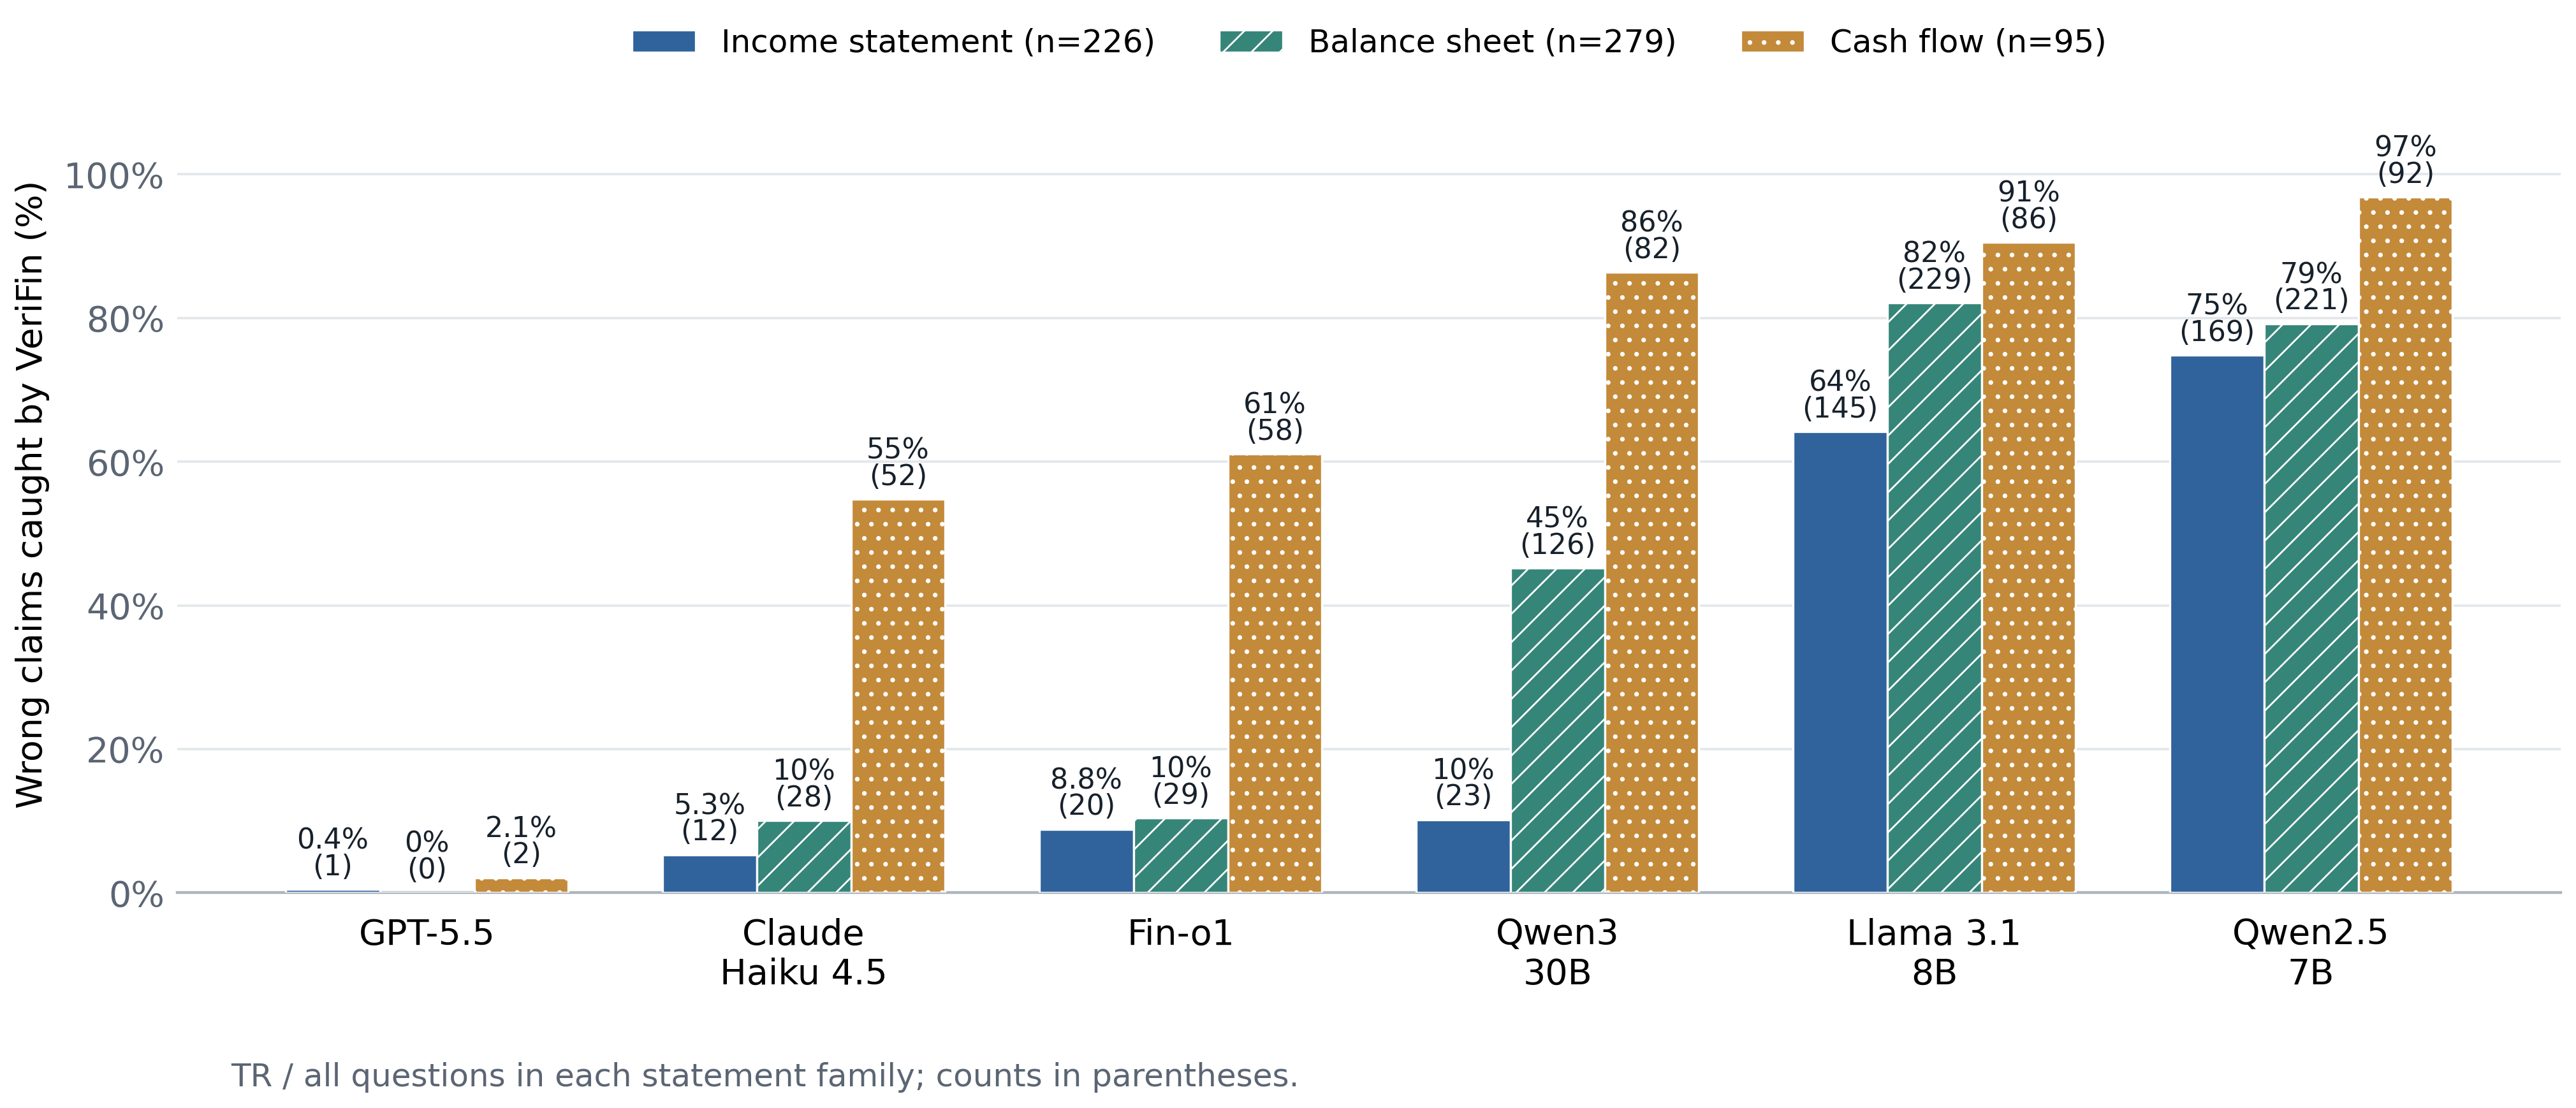

In [4]:
from matplotlib.ticker import PercentFormatter

def make_family_figure(data, totals):
    tick_labels = ["GPT-5.5", "Claude\nHaiku 4.5", "Fin-o1",
                   "Qwen3\n30B", "Llama 3.1\n8B", "Qwen2.5\n7B"]
    hatches = {"Income statement": "", "Balance sheet": "///", "Cash flow": "..."}
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                         "pdf.fonttype": 42, "ps.fonttype": 42, "hatch.linewidth": 0.5}):
        fig, ax = plt.subplots(figsize=(10.5, 4.6))
        x = np.arange(len(MODEL_ORDER))
        width = 0.25
        for offset, family in zip((-width, 0, width), FAMILY_ORDER):
            group = data[data["family"] == family].set_index("model").reindex(MODEL_ORDER)
            bars = ax.bar(x + offset, group["caught_pct"], width=width,
                          color=FAMILY_COLOR[family], edgecolor="#ffffff", linewidth=0.6,
                          hatch=hatches[family], label=f"{family} (n={totals[family]})", zorder=3)
            for bar, rate, count in zip(bars, group["caught_pct"], group["TR"]):
                rate_label = "0%" if rate == 0 else (f"{rate:.1f}%" if rate < 10 else f"{rate:.0f}%")
                ax.text(bar.get_x() + bar.get_width()/2, rate + 1.2,
                        f"{rate_label}\n({int(count)})", ha="center", va="bottom",
                        fontsize=8, linespacing=0.95, color="#17212b")
        ax.set_xticks(x, tick_labels)
        ax.set_ylim(0, 111)
        ax.set_yticks(np.arange(0, 101, 20))
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.set_ylabel("Wrong claims caught by VeriFin (%)")
        ax.grid(axis="y", color="#e5e8eb", linewidth=0.7, zorder=0)
        ax.tick_params(axis="x", length=0, pad=7)
        ax.tick_params(axis="y", length=0, labelcolor="#5b6573")
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color("#aeb5be")
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3,
                  frameon=False, fontsize=9)
        fig.text(0.12, 0.015, "TR / all questions in each statement family; counts in parentheses.",
                 fontsize=9, color="#5b6573")
        fig.subplots_adjust(left=0.10, right=0.99, bottom=0.18, top=0.86)
        return fig

family_figure = make_family_figure(family_data, family_totals)
family_stem = OUTPUT_DIR / "xbrl_error_profile_by_statement_family"
for extension in ("pdf", "svg", "png"):
    family_figure.savefig(family_stem.with_suffix("." + extension),
                          dpi=400, bbox_inches="tight", pad_inches=0.06, facecolor="white")
# Embed the exported PNG so the saved notebook shows the bar chart.
display(Image(filename=str(family_stem.with_suffix(".png")), width=1100))
plt.close(family_figure)


## Generated-answer accuracy by financial metric

All questions in each metric category remain in the denominator. The figure rounds to whole percentages; the CSV retains full precision.

In [5]:
def _draw_legend(fig: plt.Figure, *, top: float) -> None:
    """Draw the family-color key (Income statement / Balance sheet / Cash
    flow), centered, in a dedicated axes spanning the figure width from
    y=0 up to ``top`` (figure-fraction coordinates). Column headers stay
    as short codes (GP, OI, ...); spell those out in the LaTeX caption if
    needed -- only the three statement-family groupings get an in-figure
    legend."""

    ax = fig.add_axes([0.0, 0.0, 1.0, top])
    ax.axis("off")

    handles = [
        Patch(facecolor=FAMILY_COLOR[family], edgecolor="none")
        for family in FAMILY_ORDER
    ]
    ax.legend(
        handles,
        FAMILY_ORDER,
        loc="center",
        ncol=3,
        frameon=False,
        fontsize=5.1,
        handlelength=1.1,
        handleheight=1.0,
        columnspacing=1.3,
        handletextpad=0.5,
        borderaxespad=0.0,
        labelcolor=INK,
    )


def make_figure(
    accuracy_pct: pd.DataFrame,
    correct_counts: pd.DataFrame,
    denominators: pd.Series,
    output_stem: Path,
) -> plt.Figure:
    """Plot six models against 15 metrics, with family-colored headers."""

    matrix = accuracy_pct.T.reindex(columns=METRIC_ORDER).reindex(index=list(MODEL_ORDER)).to_numpy(
        dtype=float
    )
    n_cols = matrix.shape[1]
    n_rows = matrix.shape[0]

    with plt.rc_context(
        {
            "font.family": "sans-serif",
            "font.sans-serif": [
                "Liberation Sans",
                "Arial",
                "Helvetica Neue",
                "Helvetica",
                "DejaVu Sans",
            ],
            "font.size": 6.0,
            "axes.linewidth": 0.6,
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
            "svg.fonttype": "path",
            "figure.dpi": 150,
        }
    ):
        fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN), facecolor="white")

        # Room at top for the diagonal family-name labels sitting above the
        # color bar (plus a hair of margin so the bar itself isn't clipped).
        header_in = 0.91
        legend_gap_in = 0.12
        top = 1.0 - header_in / FIG_HEIGHT_IN
        heatmap_bottom = (LEGEND_HEIGHT_IN + legend_gap_in) / FIG_HEIGHT_IN
        ax = fig.add_axes([0.185, heatmap_bottom, 0.995 - 0.185, top - heatmap_bottom])

        norm = Normalize(vmin=0.0, vmax=100.0)
        for row in range(n_rows):
            for column in range(n_cols):
                value = matrix[row, column]
                ax.add_patch(
                    Rectangle(
                        (column - 0.5, row - 0.5),
                        1.0,
                        1.0,
                        facecolor=HEATMAP_CMAP(norm(value)),
                        edgecolor="none",
                    )
                )

        for row in range(n_rows):
            for column in range(n_cols):
                value = matrix[row, column]
                ax.text(
                    column,
                    row,
                    _format_pct(value),
                    ha="center",
                    va="center",
                    color="white" if value >= 66.0 else INK,
                    fontsize=5.1,
                    fontweight="semibold",
                )

        ax.set_xticks([])

        ax.set_yticks(np.arange(n_rows))
        ax.set_yticklabels(MODEL_ROW_LABELS, fontsize=5.8, color=INK)
        ax.tick_params(axis="y", length=0, pad=3.5)

        ax.set_xticks(np.arange(-0.5, n_cols, 1.0), minor=True)
        ax.set_yticks(np.arange(-0.5, n_rows, 1.0), minor=True)
        ax.grid(which="minor", color="white", linewidth=0.9)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Family column boundaries (columns re-index from 0 now that the
        # Overall/All column is gone).
        family_bounds = {
            "Income statement": (-0.5, 4.5),
            "Balance sheet": (4.5, 11.5),
            "Cash flow": (11.5, 14.5),
        }
        for boundary, linewidth in ((4.5, 0.9), (11.5, 0.9)):
            ax.axvline(boundary, color=SEPARATOR, linewidth=linewidth, alpha=0.92, zorder=5)

        # Slim colored family bar sitting just above the grid.
        for family, (left, right) in family_bounds.items():
            ax.add_patch(
                Rectangle(
                    (left, -0.5),
                    right - left,
                    -0.22,
                    facecolor=FAMILY_COLOR[family],
                    edgecolor="none",
                    clip_on=False,
                    transform=ax.transData,
                )
            )

        # Each individual metric name, written diagonally above its own
        # column, colored by which statement family it belongs to.
        for column, metric in enumerate(METRIC_ORDER):
            ax.text(
                column - 0.5 + 0.08,
                -0.78,
                metric,
                ha="left",
                va="bottom",
                rotation=83,
                rotation_mode="anchor",
                fontsize=4.4,
                fontweight="semibold",
                color=FAMILY_COLOR[METRIC_FAMILY[metric]],
                clip_on=False,
            )

        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.add_patch(
            Rectangle(
                (-0.5, -0.5),
                n_cols,
                n_rows,
                fill=False,
                edgecolor="#D0CBD6",
                linewidth=0.6,
                clip_on=False,
            )
        )
        ax.set_xlim(-0.5, n_cols - 0.5)
        ax.set_ylim(n_rows - 0.5, -0.5)

        _draw_legend(fig, top=heatmap_bottom - 0.01)

        output_stem = Path(output_stem)
        output_stem.parent.mkdir(parents=True, exist_ok=True)
        export_options = {"facecolor": "white"}
        fig.savefig(output_stem.with_suffix(".pdf"), **export_options)
        fig.savefig(output_stem.with_suffix(".svg"), **export_options)
        fig.savefig(output_stem.with_suffix(".png"), dpi=PNG_DPI, **export_options)
        return fig


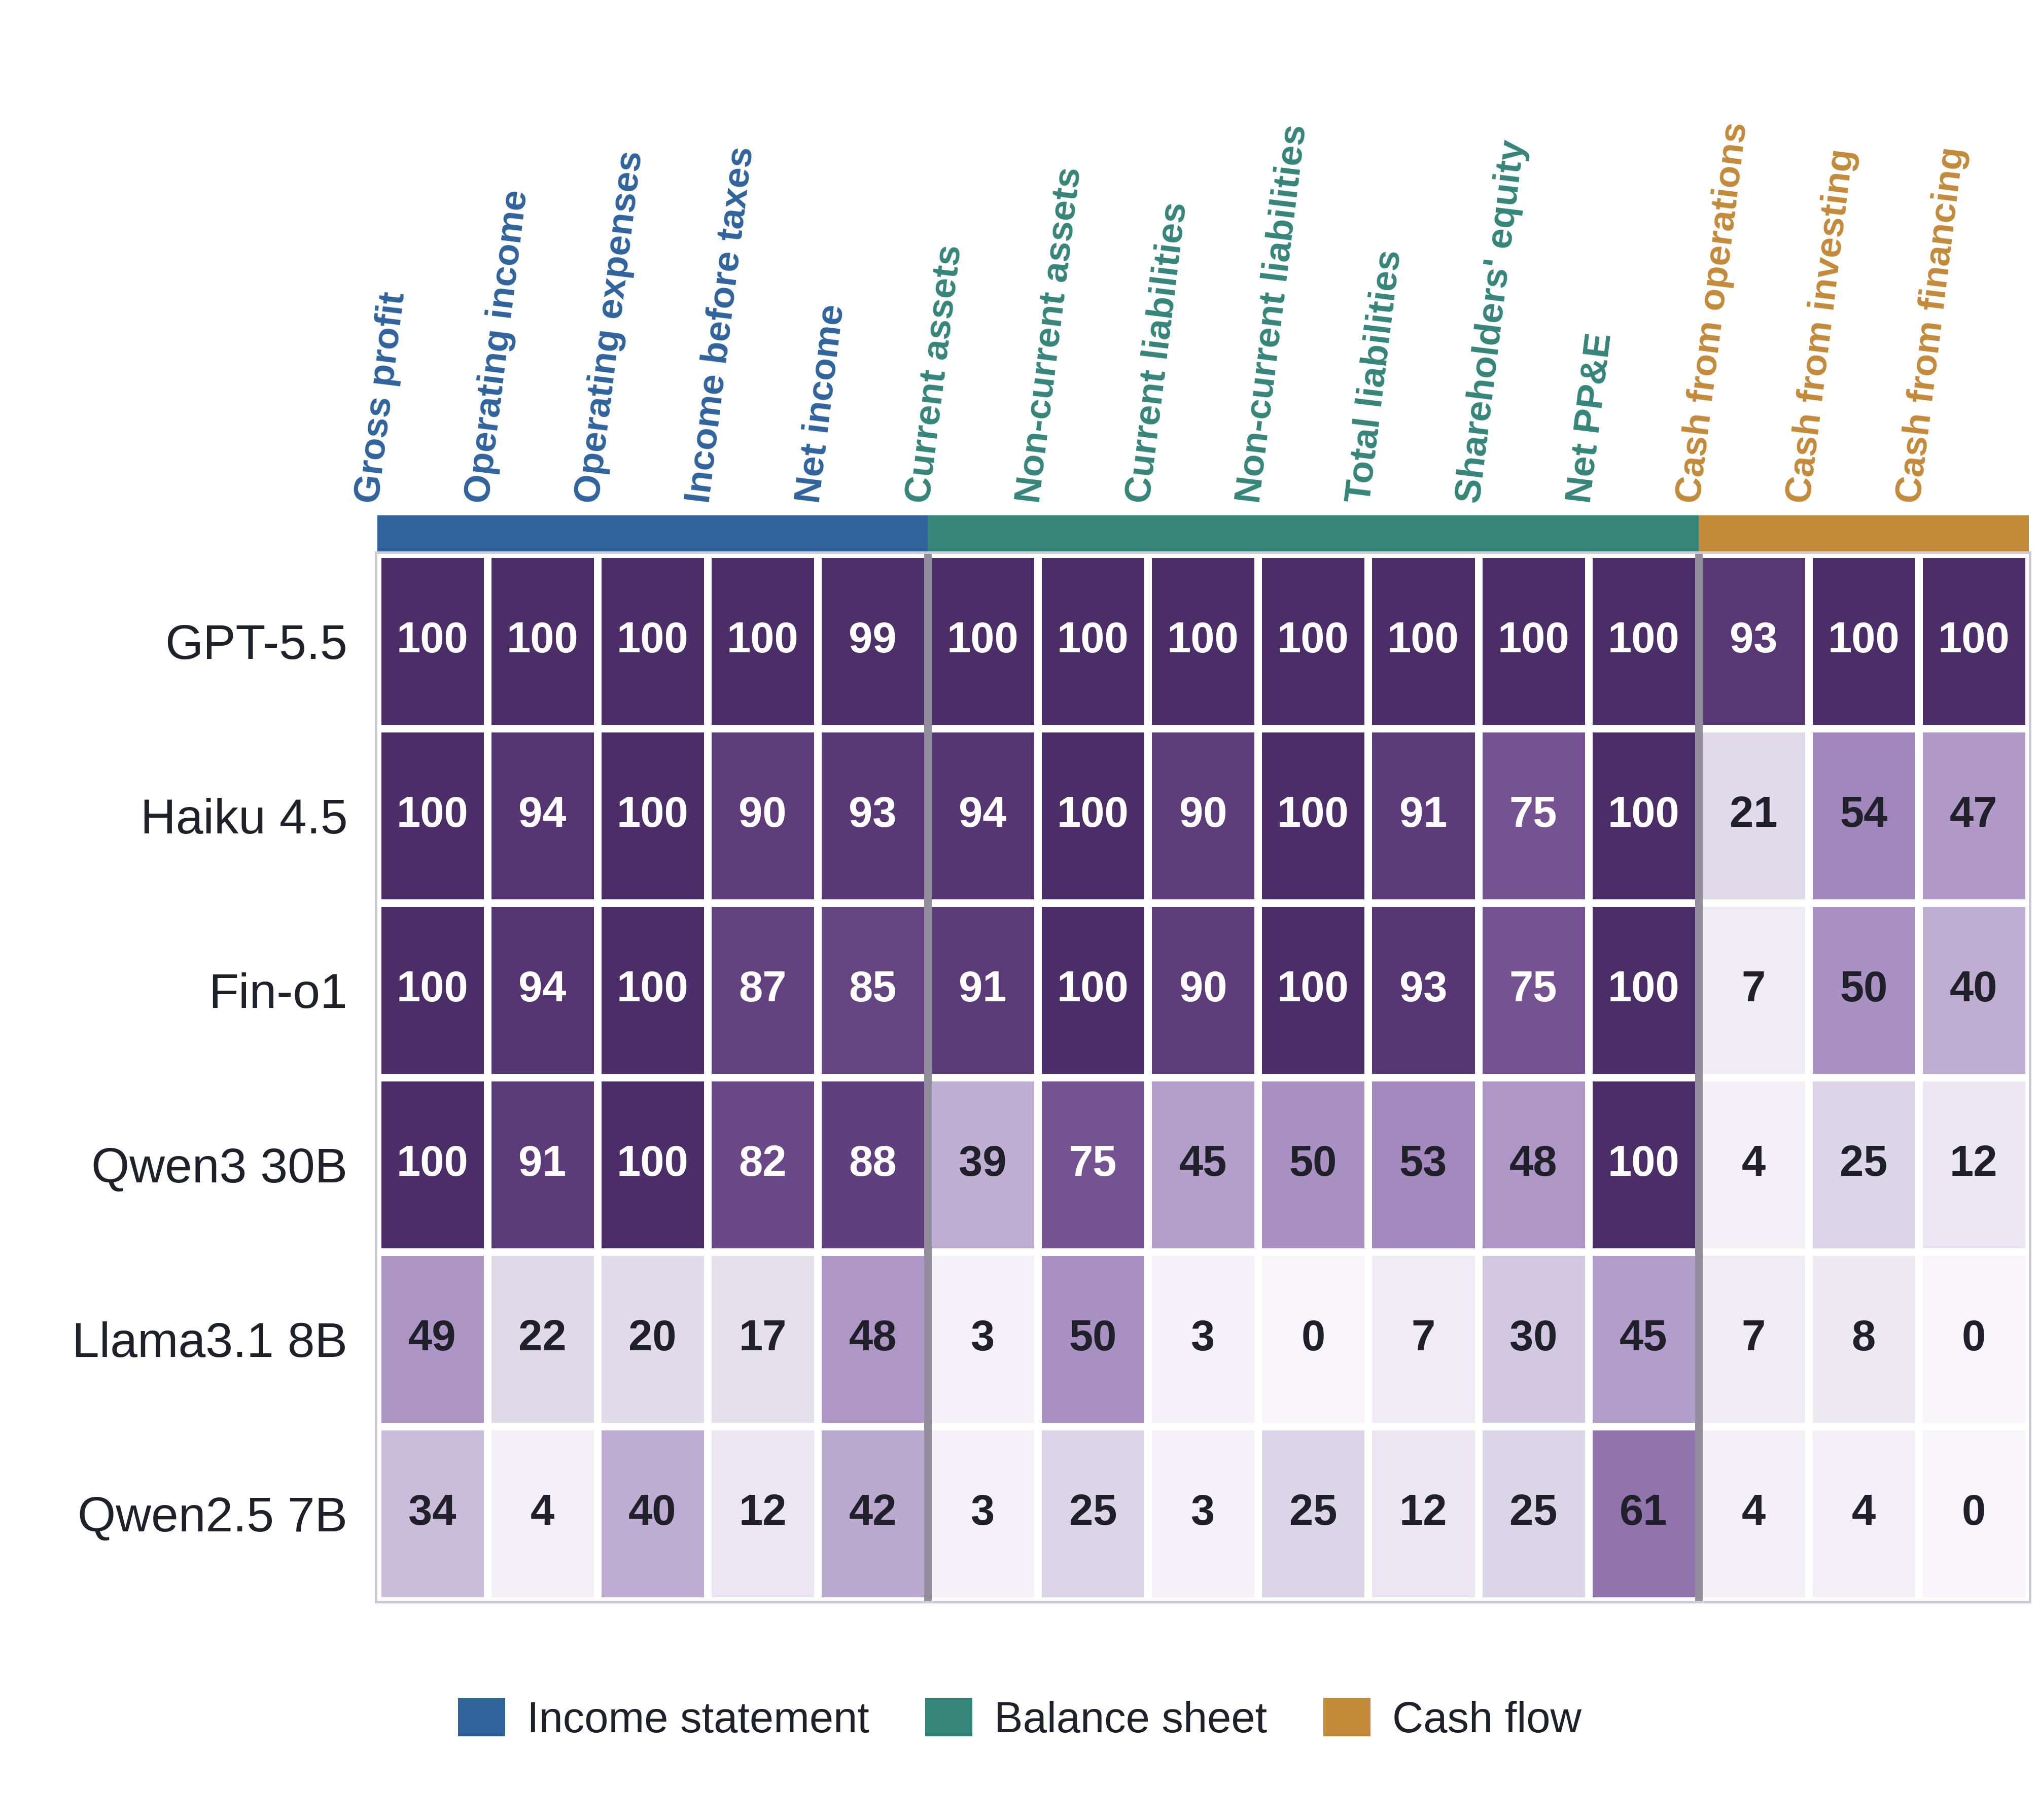

In [6]:
figure = make_figure(accuracy_pct, correct_counts, denominators, output_stem)
# Input hashes protect against changing live results during Run All.
for relative, digest in input_hashes.items():
    if hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() != digest:
        raise ValueError(f"Input changed during calculation: {relative}")
source_data.to_csv(output_stem.with_name(output_stem.name + "_data.csv"),
                   index=False, float_format="%.6f")
provenance = {
    "dataset": "XBRLFiling", "questions_per_model": N_QUESTIONS,
    "measure": "generated_answer_accuracy_before_verification",
    "scoring": "abs(abs(candidate)-abs(gold)) <= max(1, 0.01*abs(gold)); USD millions",
    "restored_from": {
        "notebook": "notebooks/agent_financebench_result_metrics.ipynb",
        "sha256": "49adc508f76c99dc69239de28ac8e7afade4c5d44407e08cb62a7b2cedbde309", "cell_id": "6067ea38",
        "original_cell_sha256": "c5265db8ad97076b0b9e10cb6526f7bd8d76e0b544fae1152092002982d19845",
        "changes": "Restored both plots under new_submissions; current shared run paths and hashes; Fin-o1 size unconfirmed.",
    },
    "inputs": [{"model": model, "path": relative, "sha256": input_hashes[relative]}
               for model, _, relative in MODEL_SPECS],
    "metric_denominators": {metric: int(n) for metric, n in denominators.items()},
    "fin_o1_checkpoint_identity": "unconfirmed",
}
output_stem.with_name(output_stem.name + "_provenance.json").write_text(
    json.dumps(provenance, indent=2) + "\n")
# Embed the exported PNG so the saved notebook shows the heatmap.
display(Image(filename=str(output_stem.with_suffix(".png")), width=1000))
plt.close(figure)


## Plotted values and exports

Exact heatmap values and per-metric denominators appear below. Exports are beside this notebook:

- Grouped bars: [PDF](figures/xbrl_error_profile_by_statement_family.pdf), [PNG](figures/xbrl_error_profile_by_statement_family.png), [CSV](figures/xbrl_error_profile_by_statement_family_data.csv).
- Heatmap: [PDF](figures/category_model_performance_1col_compact.pdf), [PNG](figures/category_model_performance_1col_compact.png), [CSV](figures/category_model_performance_1col_compact_data.csv).
- [Per-question outcomes](figures/xbrl_plot_question_outcomes.csv), [verifier counts](figures/xbrl_verifier_outcomes.csv), and [provenance](figures/six_model_plots_provenance.json).


In [7]:
plotted_values = accuracy_pct.copy()
plotted_values.insert(0, "Questions", denominators)
display(plotted_values.style.format({
    "Questions": "{:.0f}", **{model: "{:.2f}%" for model in MODEL_ORDER},
}).set_caption("Source values for the heatmap; correct counts / questions × 100"))


Answer model,Questions,GPT-5.5,Claude Haiku 4.5,Fin-o1,Qwen3-30B,Llama-3.1-8B,Qwen2.5-7B
Metric,,,,,,,
Gross profit,35,100.00%,100.00%,100.00%,100.00%,48.57%,34.29%
Operating income,54,100.00%,94.44%,94.44%,90.74%,22.22%,3.70%
Operating expenses,10,100.00%,100.00%,100.00%,100.00%,20.00%,40.00%
Income before taxes,60,100.00%,90.00%,86.67%,81.67%,16.67%,11.67%
Net income,67,98.51%,92.54%,85.07%,88.06%,47.76%,41.79%
Current assets,64,100.00%,93.75%,90.62%,39.06%,3.12%,3.12%
Non-current assets,4,100.00%,100.00%,100.00%,75.00%,50.00%,25.00%
Current liabilities,60,100.00%,90.00%,90.00%,45.00%,3.33%,3.33%
Non-current liabilities,4,100.00%,100.00%,100.00%,50.00%,0.00%,25.00%


In [8]:
# Protect the exported analysis against changing live input files.
for relative, digest in input_hashes.items():
    if hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() != digest:
        raise ValueError(f"Input changed during notebook execution: {relative}")
plot_provenance = {
    "dataset": "XBRLFiling", "questions_per_model": N_QUESTIONS,
    "run_catalog": "scripts/submission_runs.py",
    "notebook": "results/new_submissions/six_model_accuracy_heatmap.ipynb",
    "inputs": [{"path": relative, "sha256": digest} for relative, digest in input_hashes.items()],
    "models": [{"model": model, "results": relative} for model, _, relative in MODEL_SPECS],
    "family_denominators": family_totals,
    "bar_measure": "100*TR/all questions in the statement family; not verifier recall",
    "heatmap_measure": "100*correct numerical candidates/all questions in the metric; missing candidates are incorrect",
    "scoring": "Historical magnitude rule and original manual adjudications, matching the six-model table.",
    "outcome_counts": outcome_summary.to_dict(orient="index"),
    "fin_o1_checkpoint_identity": "unconfirmed for historical XBRLFiling run",
    "bar_restored_from": {
        "notebook": "to_be_deleted/archive/repository_cleanup_20261014/notebooks/agent_financebench_result_metrics.ipynb",
        "cell_id": "c0911c9c",
        "changes": "Current shared run paths; actual abstentions reported; editable plotting code."},
    "model_inference_performed": False,
}
plot_provenance["exports"] = [{"path": str(path.relative_to(ROOT)),
    "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in sorted(OUTPUT_DIR.iterdir()) if path.is_file() and path.name != "six_model_plots_provenance.json"]
(OUTPUT_DIR / "six_model_plots_provenance.json").write_text(json.dumps(plot_provenance, indent=2) + "\n")
print("Validated six complete runs and both figures. Exports:", OUTPUT_DIR.relative_to(ROOT))


Validated six complete runs and both figures. Exports: results/new_submissions/figures
